# Fairness Audit of an AI Model for Pre-Approved Credit-Card Offers
**Subject:** Responsible and Safe AI (AIML4001) - External Practical, Set C  
**Dataset:** Adult Census Income (`adult.csv`) | **Sensitive attribute:** sex  
**Name / Enrollment No.:** rudra patel 23ce106  
**GitHub:** https://github.com/ptlrudra16/RSA-Fairness-Audit.git;

**Aim:** Audit a Logistic Regression income classifier for bias across sex, apply Fairlearn's ThresholdOptimizer (demographic parity and equalized odds), and explain the accuracy-fairness trade-off.

In [4]:
!pip install fairlearn

In [5]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate,
    false_positive_rate, demographic_parity_difference, demographic_parity_ratio,
    equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer

SEED = 42
DATA = "adult.csv"

## Task 1: Load, clean, encode, scale and train (without `sex`)

In [6]:
df = pd.read_csv(DATA, skipinitialspace=True)
print("Raw shape:", df.shape)
df = df.replace("?", np.nan).dropna().reset_index(drop=True)   # remove rows with '?'
print("Shape after removing '?' rows:", df.shape)

y = (df["income"].str.strip() == ">50K").astype(int)
sex = df["sex"].str.strip()
X = df.drop(columns=["income", "sex"])                          # sex NOT a feature

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

X_tr, X_te, y_tr, y_te, s_tr, s_te = train_test_split(
    X, y, sex, test_size=0.30, random_state=SEED, stratify=y)
print("Train:", X_tr.shape, " Test:", X_te.shape)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
model.fit(X_tr, y_tr)

Raw shape: (32561, 15)
Shape after removing '?' rows: (30162, 15)
Train: (21113, 13)  Test: (9049, 13)


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'fnlwgt',
                                                   'education.num',
                                                   'capital.gain',
                                                   'capital.loss',
                                                   'hours.per.week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['workclass', 'education',
                                                   'marital.status',
                                                   'occupation', 'relationship',
                                                   'race',
                                                   'native.country'])])),
                ('clf', LogisticRegression(max_iter=1000))])

## Task 2: Overall accuracy and MetricFrame by sex

In [7]:
y_pred = model.predict(X_te)
base_acc = accuracy_score(y_te, y_pred)
print(f"Baseline model : Logistic Regression   Accuracy : {base_acc:.2f}")

def audit(y_true, y_hat, sens):
    return MetricFrame(
        metrics={"accuracy": accuracy_score, "selection_rate": selection_rate,
                 "tpr": true_positive_rate, "fpr": false_positive_rate},
        y_true=y_true, y_pred=y_hat, sensitive_features=sens)

mf = audit(y_te, y_pred, s_te)
print("\nGROUP     ACCURACY  SELECTION_RATE   TPR    FPR")
print("-" * 52)
for g in ["Male", "Female"]:
    r = mf.by_group.loc[g]
    print(f"{g:<8}  {r.accuracy:.2f}      {r.selection_rate:.2f}            {r.tpr:.2f}   {r.fpr:.2f}")
print("-" * 52)

Baseline model : Logistic Regression   Accuracy : 0.85

GROUP     ACCURACY  SELECTION_RATE   TPR    FPR
----------------------------------------------------
Male      0.82      0.26            0.62   0.09
Female    0.92      0.09            0.53   0.03
----------------------------------------------------


## Task 3: Demographic parity difference/ratio and equalized odds difference

In [8]:
def fair_metrics(y_true, y_hat, sens):
    return (demographic_parity_difference(y_true, y_hat, sensitive_features=sens),
            demographic_parity_ratio(y_true, y_hat, sensitive_features=sens),
            equalized_odds_difference(y_true, y_hat, sensitive_features=sens))

dpd, dpr, eod = fair_metrics(y_te, y_pred, s_te)
print(f"Demographic parity difference : {dpd:.2f}")
print(f"Demographic parity ratio (DI) : {dpr:.2f} ({'< 0.80 -> BIAS' if dpr < 0.8 else '>= 0.80 -> PASS'})")
print(f"Equalized odds difference     : {eod:.2f}")

Demographic parity difference : 0.17
Demographic parity ratio (DI) : 0.34 (< 0.80 -> BIAS)
Equalized odds difference     : 0.08


## Tasks 4 and 5: ThresholdOptimizer (demographic parity, equalized odds)

In [9]:
Xtr_t = model.named_steps["pre"].transform(X_tr)
Xte_t = model.named_steps["pre"].transform(X_te)
clf = model.named_steps["clf"]

results = {"Baseline": (y_pred, mf)}
for name, cons in [("TO: demographic_par.", "demographic_parity"),
                   ("TO: equalized_odds", "equalized_odds")]:
    to = ThresholdOptimizer(estimator=clf, constraints=cons, objective="accuracy_score",
                            prefit=True, predict_method="predict_proba")
    to.fit(Xtr_t, y_tr, sensitive_features=s_tr)
    yp = to.predict(Xte_t, sensitive_features=s_te, random_state=SEED)
    results[name] = (yp, audit(y_te, yp, s_te))
    d, r_, e = fair_metrics(y_te, yp, s_te)
    print(f"=== ThresholdOptimizer: {cons} ===")
    print(f"Accuracy {accuracy_score(y_te, yp):.2f}")
    print(audit(y_te, yp, s_te).by_group.round(2).to_string())
    print(f"DP diff {d:.2f} | DP ratio {r_:.2f} | EO diff {e:.2f}\n")

=== ThresholdOptimizer: demographic_parity ===
Accuracy 0.83
        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.89            0.17  0.77  0.10
Male        0.80            0.18  0.47  0.04
DP diff 0.00 | DP ratio 0.99 | EO diff 0.30

=== ThresholdOptimizer: equalized_odds ===
Accuracy 0.83
        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.87            0.14  0.55  0.09
Male        0.81            0.23  0.57  0.07
DP diff 0.09 | DP ratio 0.61 | EO diff 0.02



## Task 6: Accuracy vs fairness comparison table and selection-rate plot

In [10]:
rows = []
for name, (yp, m) in results.items():
    d, r_, e = fair_metrics(y_te, yp, s_te)
    rows.append(dict(MODEL=name, ACC=accuracy_score(y_te, yp),
                     SEL_M=m.by_group.loc["Male", "selection_rate"],
                     SEL_F=m.by_group.loc["Female", "selection_rate"],
                     DP_DIFF=d, DP_RATIO=r_, EO_DIFF=e))
comp = pd.DataFrame(rows).round(2)
comp.to_csv("comparison_table.csv", index=False)
comp

,MODEL,ACC,SEL_M,SEL_F,DP_DIFF,DP_RATIO,EO_DIFF
0,Baseline,0.85,0.26,0.09,0.17,0.34,0.08
1,TO: demographic_par.,0.83,0.18,0.17,0.00,0.99,0.30
2,TO: equalized_odds,0.83,0.23,0.14,0.09,0.61,0.02


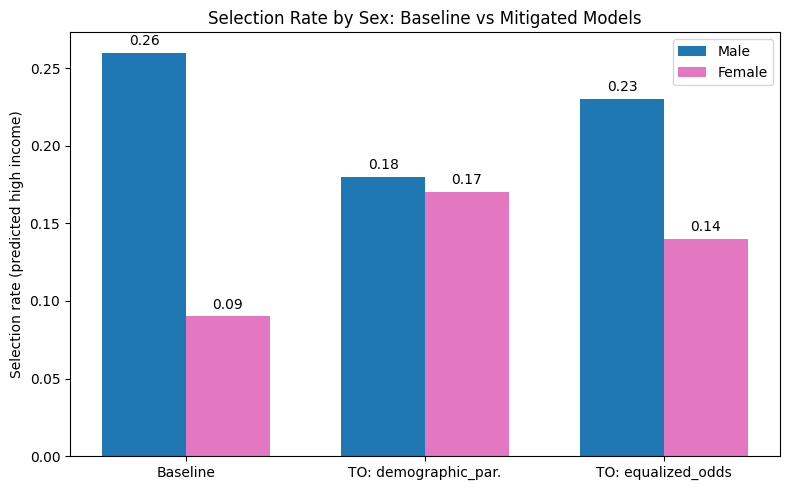

Plot saved : selection_rate_by_sex.png


In [11]:
x = np.arange(len(comp)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, comp.SEL_M, w, label="Male", color="#1f77b4")
b2 = ax.bar(x + w/2, comp.SEL_F, w, label="Female", color="#e377c2")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005, f"{b.get_height():.2f}", ha="center")
ax.set_xticks(x); ax.set_xticklabels(comp.MODEL)
ax.set_ylabel("Selection rate (predicted high income)")
ax.set_title("Selection Rate by Sex: Baseline vs Mitigated Models")
ax.legend(); plt.tight_layout()
plt.savefig("selection_rate_by_sex.png", dpi=150)
plt.show()
print("Plot saved : selection_rate_by_sex.png")

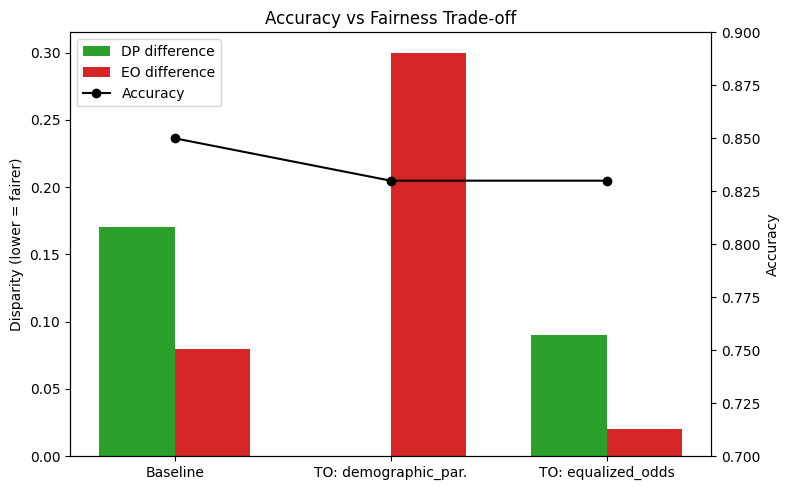

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - w/2, comp.DP_DIFF, w, label="DP difference", color="#2ca02c")
ax.bar(x + w/2, comp.EO_DIFF, w, label="EO difference", color="#d62728")
ax2 = ax.twinx(); ax2.plot(x, comp.ACC, "ko-", label="Accuracy"); ax2.set_ylim(0.7, 0.9)
ax2.set_ylabel("Accuracy"); ax.set_ylabel("Disparity (lower = fairer)")
ax.set_xticks(x); ax.set_xticklabels(comp.MODEL); ax.set_title("Accuracy vs Fairness Trade-off")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left"); plt.tight_layout()
plt.savefig("accuracy_vs_fairness.png", dpi=150)
plt.show()

## Conclusion
The baseline model never sees `sex`, yet selects men (0.26) about three times as often as women (0.09) and fails the four-fifths rule (DI = 0.34), because of proxy features and biased historical data. ThresholdOptimizer reduces the disparity at a cost of about 2 percentage points of accuracy (0.85 to 0.83). Demographic parity and equalized odds cannot both be satisfied: fixing one worsens or only partly improves the other.

## Answers to Technical Questions
**Q1.** Overall accuracy 0.85. Male: selection 0.26, TPR 0.62, FPR 0.09. Female: selection 0.09, TPR 0.53, FPR 0.03. Women are disadvantaged (far fewer offers, lower TPR). Their higher accuracy is misleading because most women are low income and the model predicts "low income" for most of them.

**Q2.** DP difference 0.17, DP ratio 0.34, EO difference 0.08. The model fails the four-fifths rule (0.34 < 0.80). Bias persists without `sex` because proxy features (relationship, marital status, occupation, hours per week) correlate with sex and the historical labels carry real income gaps.

**Q3.** *Demographic parity:* DP diff 0.00 but EO diff rises from 0.08 to 0.30. *Equalized odds:* EO diff 0.02 but DP diff only improves partly (0.17 to 0.09, ratio 0.61). The two definitions conflict when base rates differ.

**Q4.** Accuracy falls from 0.85 to 0.83 (about 2 points). Recommended: equalized odds, since equally qualified men and women get near-equal chances of an offer (TPR 0.55 vs 0.57) with the same accuracy cost; it still falls short of the 0.80 rule, so keep monitoring. Limitation: ThresholdOptimizer needs the sensitive attribute at prediction time and uses group-specific, randomized thresholds, which can be disparate treatment and does not fix the underlying data.